# 18-T800踢着物体走


## 1. 本课目标：把感知、规划和控制连起来

本篇对应《具身智能机器人实战》第 18 节《T800 踢着物体走》，副标题为“感知规划控制”。上一节在世界中创建了木块，本节进一步讨论：机器人怎样获得木块的信息、判断相对位置，再选择运动动作。

**资料依据：**[课程百度网盘资料](https://pan.baidu.com/s/1TI1Opoqy_jjmWCzhUOwliw?pwd=1234)，提取码 `1234`。已逐页核对 `ppt/18_让机器人踢着木块走路.pptx` 全部 6 页：第 2 页介绍机器人控制流程，第 3 页介绍目标检测，第 4 页介绍 RGB-D 深度信息，第 5 页介绍根据位置关系选择动作，第 6 页为品牌结束页。

课件以流程和示意图为主，没有提供检测模型、深度处理代码、动作判断条件或踢击参数。下面按课件顺序解释各环节，必要的概念区分标为“工程补充”。未转录配套视频 `18_T800踢着木块往前走.mp4`，也未读取网盘中的 `code.zip`。


## 2. 机器人控制流程：感知、规划、控制

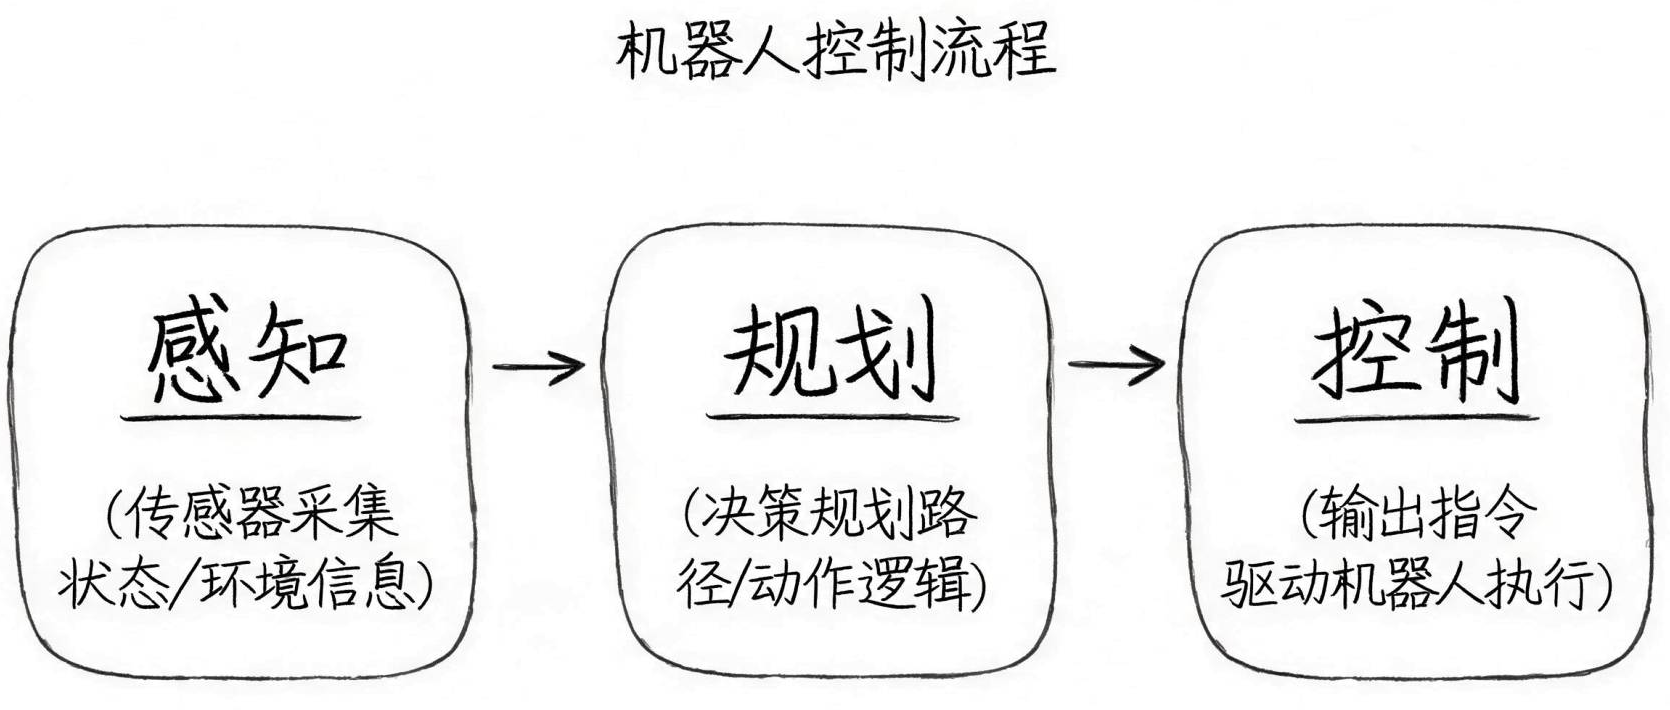

*原课件第 2 页：感知采集状态和环境信息，规划决定路径或动作逻辑，控制输出指令并驱动机器人执行。*

课件把任务分成三个环节：

| 环节 | 课件中的职责 | 在木块任务中需要回答的问题 |
|---|---|---|
| 感知 | 传感器采集状态、环境信息 | 木块在哪里，机器人与它处于什么位置关系 |
| 规划 | 决策规划路径、动作逻辑 | 接下来应该朝哪个方向运动，选什么动作 |
| 控制 | 输出指令，驱动机器人执行 | 怎样把选定动作落实为机器人的运动 |

这三个环节提供了理解任务的顺序。先获得信息，才有依据决定动作；作出决定后，还需要控制系统执行。图中画的是职责流程，并没有指定使用哪一种路径规划算法或关节控制器。

**工程补充：**机器人运动、木块受到接触后，两者的位置关系会变化。持续执行任务时，需要再次感知并更新决策，形成反馈过程。一次判断后一直执行同一动作，不能体现这种持续更新。


## 3. 目标检测：在画面中识别木块

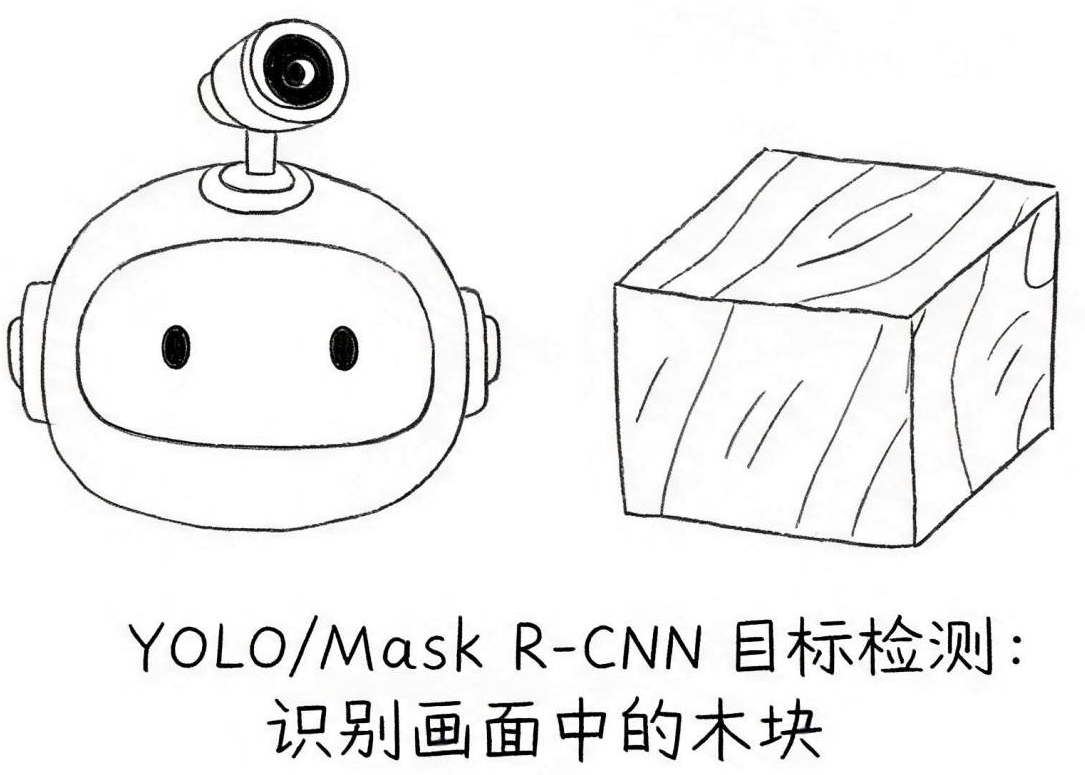

*原课件第 3 页：“YOLO/Mask R-CNN 目标检测：识别画面中的木块”。*

感知首先需要找到任务对象。课件列出 YOLO 和 Mask R-CNN，用来说明可以从相机画面中识别木块。识别到对象及其图像位置后，后续环节才知道应该关注画面中的哪个区域。

这里解决的是“画面里哪个是木块”。仅找到图像中的目标，还不足以确定机器人离它多远，所以课件接着引入深度信息。

**工程补充：**目标检测常提供类别、置信度和图像框；Mask R-CNN 还可提供实例分割掩码，描述目标所占的像素区域。课件没有给出具体模型版本、训练类别、权重或推理结果，列出算法名称不表示已经完成本任务的检测部署，也不能据此认为前面策略的 1083 维输入已包含图像。


## 4. RGB-D 深度相机：补充距离信息

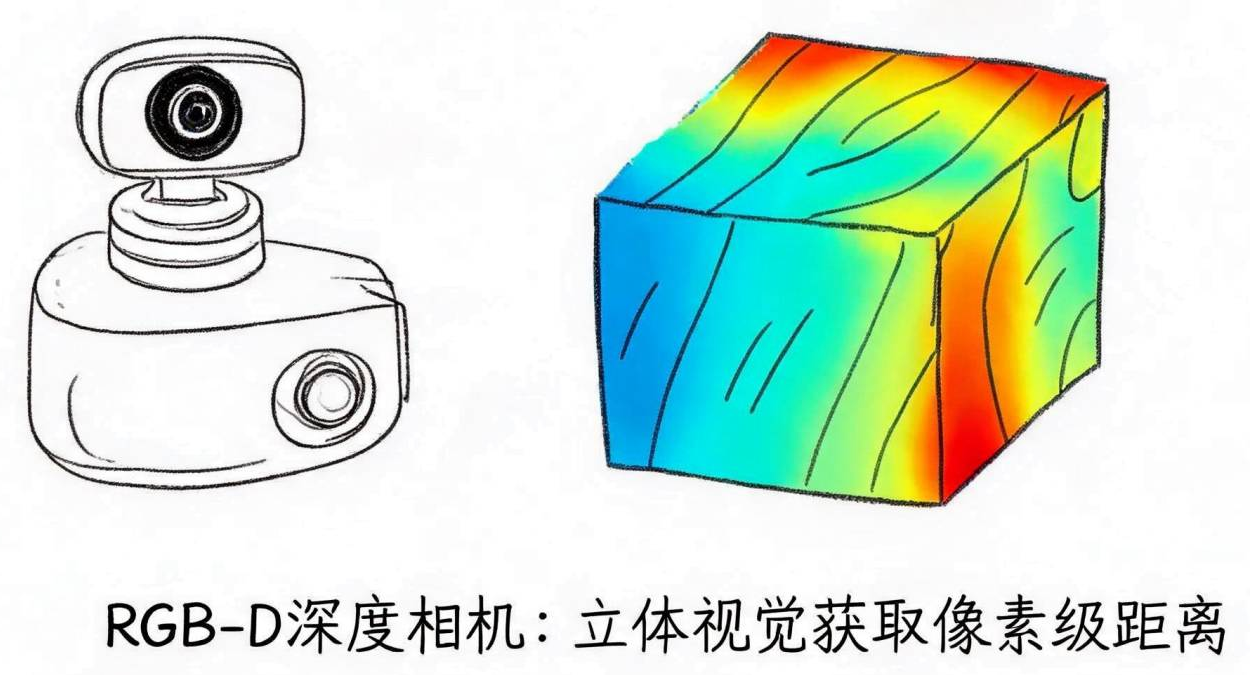

*原课件第 4 页：“RGB-D 深度相机：立体视觉获取像素级距离”。木块上的彩色渐变用来示意深度信息。*

RGB-D 中，RGB 对应彩色图像，D 对应深度（Depth）。彩色图像帮助识别目标，深度数据为相应像素提供距离相关信息，让感知进一步从“看见木块”走向“了解它的位置”。

把目标所在的图像区域与深度数据对应起来，才能为后面的相对位置判断提供距离依据。图中的颜色用于表达深度差异，课件没有给出颜色与距离的对应标尺，不能从图中读出木块的实际距离。

**工程补充：**课件以立体视觉解释深度获取，但 RGB-D 是数据形式，不限定所有设备都采用同一种测距原理。具体使用深度值时，还需核对单位、无效值及彩色图与深度图是否对齐；若要得到机器人坐标系中的三维位置，还涉及相机参数与坐标变换。课件未提供这些配置，不能直接把像素坐标当成世界坐标。


## 5. 根据位置关系选择动作，再交给控制执行

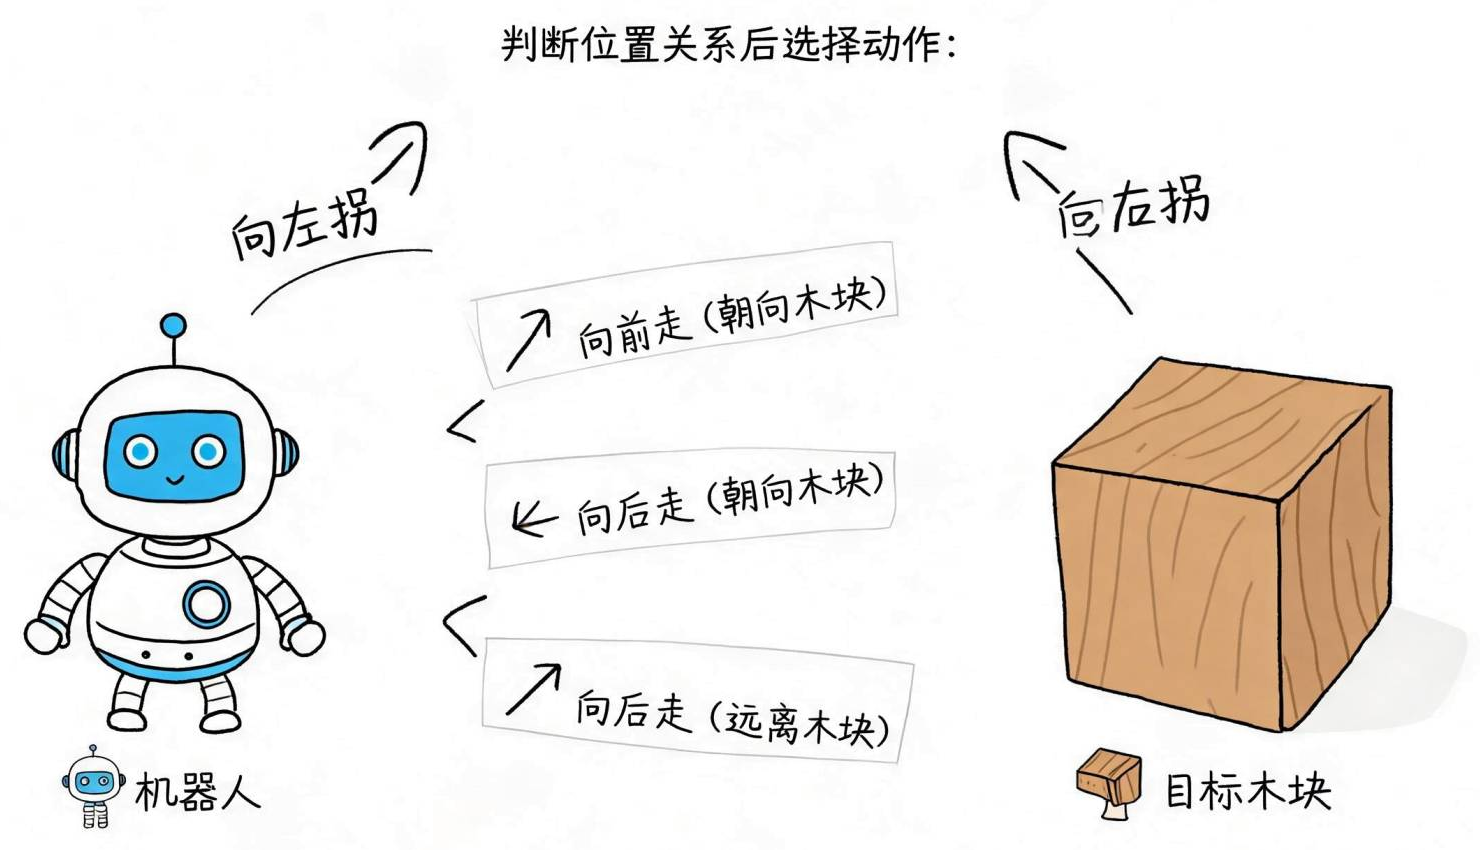

*原课件第 5 页：判断位置关系后选择动作，图中列出左右转向和前后移动。*

获得目标信息后，规划环节需要根据机器人与木块的位置关系选择动作。课件列出的动作文字如下：

| 动作类型 | 图中标注 |
|---|---|
| 转向 | “向左拐”“向右拐” |
| 前进 | “向前走（朝向木块）” |
| 后退 | “向后走（朝向木块）”“向后走（远离木块）” |

这张图说明决策需要以位置关系为依据，没有给出每种动作的触发条件、距离阈值、运动速度或执行时长。它也没有展开脚部怎样接触木块、踢击多大或何时停止，因此不能把图中动作直接整理成一套可执行的踢木块规则。

**工程补充：**图中两处“向后走”分别配了“朝向木块”和“远离木块”，但没有标明机器人朝向和坐标系。前后运动方向相对于机器人自身，接近或远离则取决于目标的位置，两者需要结合姿态判断。这里保留原标注，不擅自把其中一项改成其他动作，也不推定它就是课程代码中的分支条件。

联系前面几节，规划可以向运动控制环节提供移动或转向意图，控制环节再生成和执行关节指令。实际使用哪种接口、是否通过第 12 节的用户命令输入，以及怎样控制接触，都需要核对实际程序。检测出木块、选出动作和成功推动木块，分别是需要验证的环节。


## 6. 本课检查

本节按“识别目标、获得深度、判断位置关系、选择并执行动作”的顺序，把木块任务放进感知、规划、控制流程中。

完成本节，应能区分图像检测结果、深度数据与机器人相对位置，解释为什么需要持续更新目标信息，并说明动作示意图还缺少哪些条件才能落实为程序。

本篇已覆盖课件全部教学页并保留 4 张教学图。已读取的课件未提供具体实现，本篇没有加载检测模型、处理深度数据、执行策略或验证 T800 踢着木块行走。
